MAE: 25.400894262811363
R²: 0.03506774498934562
              precision    recall  f1-score   support

           0       0.74      0.75      0.74      1203
           1       0.61      0.60      0.60       795

    accuracy                           0.69      1998
   macro avg       0.67      0.67      0.67      1998
weighted avg       0.69      0.69      0.69      1998



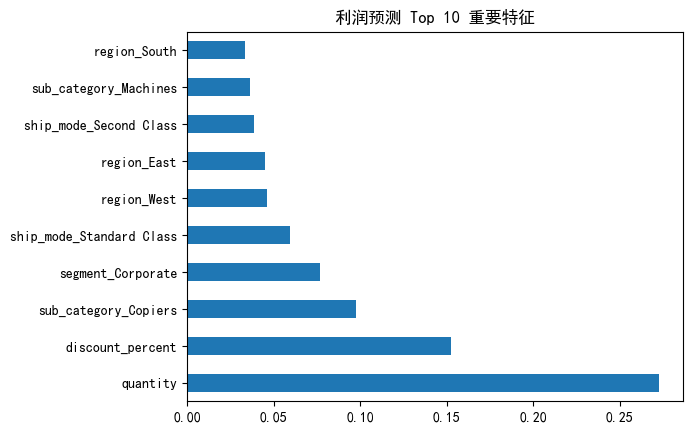

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']   # 中文显示
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv('../data/orders_cleaned.csv')
# 特征：品类、地区、配送方式等做独热编码 + 数值特征
features = pd.get_dummies(df[['ship_mode','segment','region','category','sub_category']],
                          drop_first=True)
features[['quantity','discount_percent']] = df[['quantity','discount_percent']]
X, y = features, df['profit']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print('MAE:', mean_absolute_error(y_test, pred))
print('R²:', r2_score(y_test, pred))

imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
imp.plot(kind='barh', title='利润预测 Top 10 重要特征')
plt.savefig('../visualizations/feature_importance.png', dpi=150, bbox_inches='tight')

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

y_cls = (df['profit'] < 0).astype(int)  # 1=亏损订单
X_train, X_test, y_train, y_test = train_test_split(X, y_cls, test_size=0.2, random_state=42)
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)
print(classification_report(y_test, clf.predict(X_test)))